In [14]:
import json
from pathlib import Path
import requests

# 1. API Bağlantısı
url = "https://openbookrank.com/api/v1/rankings/science-fiction.json"
headers = {"User-Agent": "Mozilla/5.0"}

# 2. Veriyi çekme (json() fonksiyonunu çağırıyoruz)
response = requests.get(url, timeout=10)
response.raise_for_status()
data = response.json()

# 3. data/raw klasörüne kaydetme
raw_path = Path("../data/raw")
raw_path.mkdir(parents=True, exist_ok=True)

with open(raw_path / "science_fiction_raw.json", "w", encoding="utf-8") as f:
    json.dump(data, f, ensure_ascii=False, indent=2)

print("Ham veri kaydedildi.")
print("Toplam kayıt sayısı:", len(data))

Ham veri kaydedildi.
Toplam kayıt sayısı: 10


In [15]:
#DataFrame dönüştürme
import json
import pandas as pd

#Ham veriyi okuma
with open("../data/raw/science_fiction_raw.json", "r", encoding="utf-8") as f:
    raw_records = json.load(f)

df = pd.json_normalize(raw_records["items"])

#Boyut ve sütun kontrolü
print("Veri Seti Boyutu (Satır, Sütun):", df.shape)
print("\nMevcut Sütunlar:")
print(df.columns.tolist())
df.head(5)

Veri Seti Boyutu (Satır, Sütun): (805, 11)

Mevcut Sütunlar:
['rank', 'id', 'slug', 'title', 'author', 'year', 'score', 'ratings', 'confidence', 'url', 'api']


,rank,id,slug,title,author,year,score,ratings,confidence,url,api
0,1,obr:work:light-bringer-54ce9,light-bringer-54ce9,Light Bringer,Pierce Brown,2023.0,9.11,636,0.812,https://openbookrank.com/en/book/light-bringer...,https://openbookrank.com/api/v1/books/light-br...
1,2,obr:work:project-hail-mary,project-hail-mary,Project Hail Mary,Andy Weir,2021.0,8.99,8300,0.983,https://openbookrank.com/en/book/project-hail-...,https://openbookrank.com/api/v1/books/project-...
2,3,obr:work:network-effect,network-effect,Network Effect,Martha Wells,2020.0,8.93,1585,0.915,https://openbookrank.com/en/book/network-effect,https://openbookrank.com/api/v1/books/network-...
3,4,obr:work:tiamats-wrath,tiamats-wrath,Tiamat's Wrath,James S. A. Corey,2019.0,8.93,1072,0.879,https://openbookrank.com/en/book/tiamats-wrath,https://openbookrank.com/api/v1/books/tiamats-...
4,5,obr:work:the-martian,the-martian,The Martian,Andy Weir,2013.0,8.84,6086,0.976,https://openbookrank.com/en/book/the-martian,https://openbookrank.com/api/v1/books/the-mart...


In [16]:
# Veri temizleme ve veriyi kaydetme
from pathlib import Path
import pandas as pd
#Araştırma sorularında kullanılacak sütunlar seçildi
selected_cols = [ "id", "rank", "title", "author", "year", "score", "ratings"]
df_clean = df[selected_cols].copy()

print("Eksik Değer Sayıları:")
print(df_clean.isna().sum())
df_clean = df_clean.dropna(subset=["title", "author", "score"])
df_clean["score"]

#Tekrar eden kayıt kontrolü
print("\nTekrar eden ID sayısı:", df_clean.duplicated(subset=["id"]).sum())
df_clean = df_clean.drop_duplicates(subset=["id"]).copy()

#Veri tiplerini  düzenleme 
df_clean["score"] = pd.to_numeric(df_clean["score"], errors="coerce")
df_clean["ratings"] = pd.to_numeric(df_clean["ratings"], errors="coerce")
#Yıl sütunundaki ondalığı tam sayıya (2023.0-> 2023) çevirme
df_clean["year"] = pd.to_numeric(df_clean["year"], errors="coerce").astype("Int64")

#Temiz veriyi data/processed klasörüne CSV olarak kaydetme 
processed_path = Path("../data/processed")
processed_path.mkdir(parents=True, exist_ok=True)
df_clean.to_csv(processed_path / "science_fiction_clean.csv", index=False)

print("\nTemizlik Sonrası Veri Boyutu:", df_clean.shape)
print(df_clean.dtypes)
df_clean.head


Eksik Değer Sayıları:
id          0
rank        0
title       0
author      0
year       18
score       0
ratings     0
dtype: int64

Tekrar eden ID sayısı: 0

Temizlik Sonrası Veri Boyutu: (805, 7)
id             str
rank         int64
title          str
author         str
year         Int64
score      float64
ratings      int64
dtype: object


<bound method NDFrame.head of                                id  rank              title             author  \
0    obr:work:light-bringer-54ce9     1      Light Bringer       Pierce Brown   
1      obr:work:project-hail-mary     2  Project Hail Mary          Andy Weir   
2         obr:work:network-effect     3     Network Effect       Martha Wells   
3          obr:work:tiamats-wrath     4     Tiamat's Wrath  James S. A. Corey   
4            obr:work:the-martian     5        The Martian          Andy Weir   
..                            ...   ...                ...                ...   
800         obr:work:dreamcatcher   801       Dreamcatcher       Stephen King   
801               obr:work:armada   802             Armada       Ernest Cline   
802           obr:work:the-circle   803         The Circle        Dave Eggers   
803            obr:work:allegiant   804          Allegiant      Veronica Roth   
804     obr:work:ready-player-two   805   Ready Player Two       Ernest Cline  

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

#Grafik ayarları
sns.set_theme(style="whitegrid")          #Daha düzenli bir paragraf
figures_path = Path("../figures")         #Grafikleri kaydedip klasör var mı yok mu kontrol eder.
figures_path.mkdir(parents=True, exist_ok=True)

print("Sayısal Değişkenlerin Özeti:")
display(df_clean[["score", "ratings", "year"]].describe())


Sayısal Değişkenlerin Özeti:


,score,ratings,year
count,805.000000,805.000000,787.0
mean,7.819093,557.445963,1995.345616
std,0.352773,979.877568,26.171775
min,6.500000,50.000000,1818.0
25%,7.590000,100.000000,1985.0
50%,7.800000,208.000000,2002.0
75%,8.010000,576.000000,2014.0
max,9.110000,9320.000000,2026.0


C:\Users\HP\AppData\Local\Temp\ipykernel_15828\2742405147.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(data=top10_books, x="score", y="title", palette="viridis")


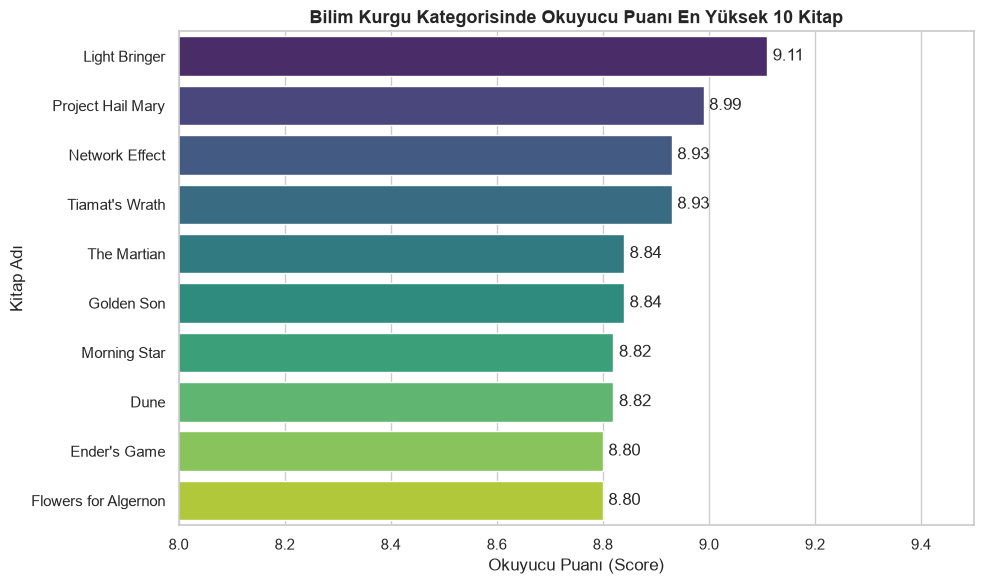

In [18]:
#SORU 1 : Okuyucu puanı (score) en yüksek 10 kitap hangileridir?
top10_books = df_clean.sort_values(by="score", ascending=False).head(10)

plt.figure(figsize =(10, 6))
ax1 = sns.barplot(data=top10_books, x="score", y="title", palette="viridis")
plt.title("Bilim Kurgu Kategorisinde Okuyucu Puanı En Yüksek 10 Kitap", fontsize=13, fontweight="bold")
plt.xlabel("Okuyucu Puanı (Score)")
plt.ylabel("Kitap Adı")
plt.xlim(8.0, 9.5)  #fakların net görülmesi için eksen aralığı

for container in ax1.containers:
    ax1.bar_label(container, fmt="%.2f", padding=4)

plt.tight_layout()
plt.savefig(figures_path / "soru1_en_yuksek_puanli_10_kitap.png", dpi=300)
plt.show()

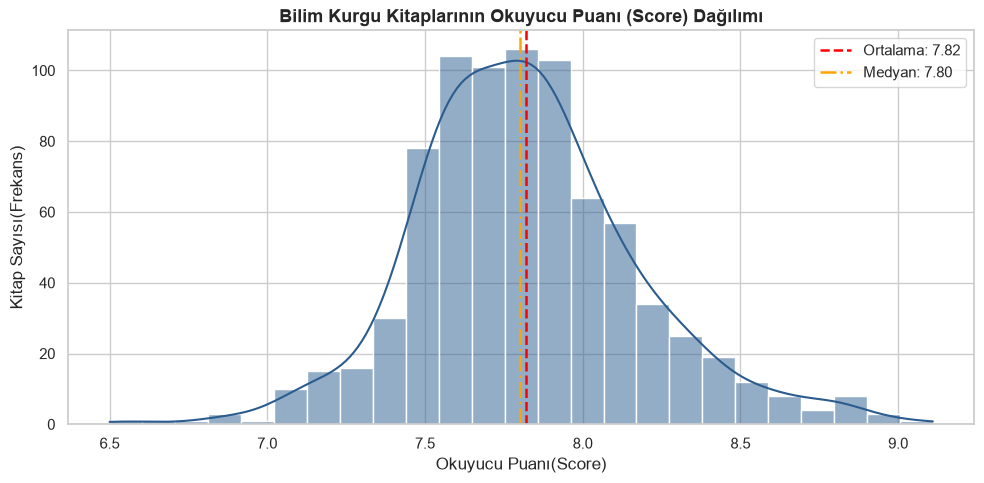

In [19]:
#SORU 2 : Kitapların puanları nasıl bir dağılım göstermektedir?

mean_score = df_clean["score"].mean()
median_score = df_clean["score"].median()

plt.figure(figsize=(10, 5))
sns.histplot(data=df_clean, x="score", bins=25, kde=True, color="#2b5c8f")
plt.axvline(mean_score, color="red", linestyle="--", linewidth=1.8, label=f"Ortalama: {mean_score:.2f}")
plt.axvline(median_score, color="orange", linestyle="-.", linewidth=1.8, label=f"Medyan: {median_score:.2f}")

plt.title("Bilim Kurgu Kitaplarının Okuyucu Puanı (Score) Dağılımı", fontsize=13, fontweight="bold")
plt.xlabel("Okuyucu Puanı(Score)")
plt.ylabel("Kitap Sayısı(Frekans)")
plt.legend()
plt.tight_layout()
plt.savefig(figures_path / "soru2_puan_dagilimi.png", dpi=300)
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_15828\2784441493.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.barplot(x=top_authors.values, y=top_authors.index, palette="magma")


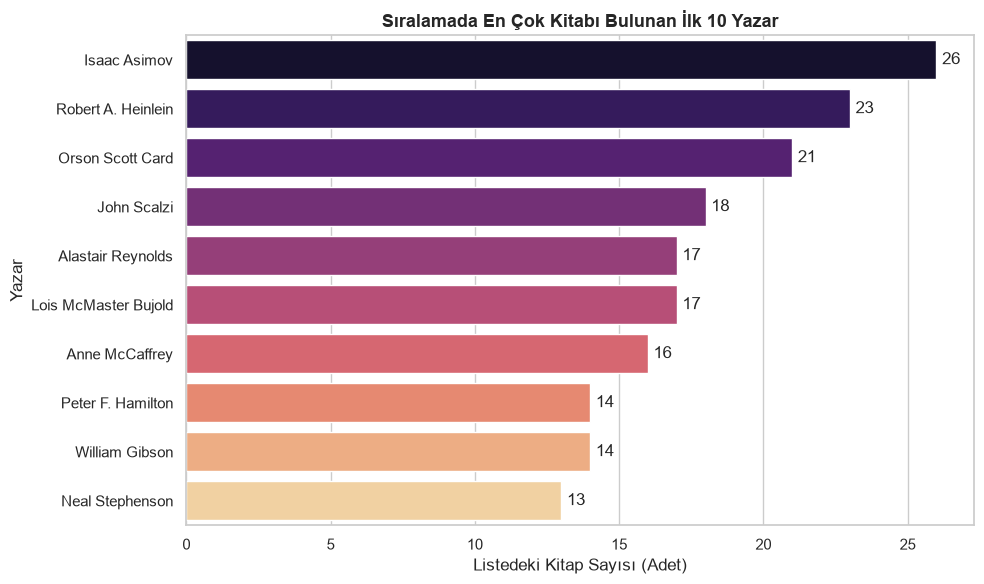

In [20]:
#SORU 3 : Sıralamada en çok kitabı bulunan yazarlar hangileridir?
top_authors = df_clean["author"].value_counts().head(10)

plt.figure(figsize=(10, 6))
ax3 = sns.barplot(x=top_authors.values, y=top_authors.index, palette="magma")
plt.title("Sıralamada En Çok Kitabı Bulunan İlk 10 Yazar", fontsize=13, fontweight="bold")
plt.xlabel("Listedeki Kitap Sayısı (Adet)")
plt.ylabel("Yazar")

for container in ax3.containers:
    ax3.bar_label(container, padding=4)

plt.tight_layout()
plt.savefig(figures_path / "soru3_en_cok_kitabı_olan_yazarlar.png", dpi=300)
plt.show()